# 🛒 Online Shoppers Purchase Intention Prediction
**NTI – Machine Learning for Data Analysis | Final Project**

---

## 1. Problem Statement

An online store wants to know **whether a browsing session will end in a purchase**, using only what the visitor did during the session (pages visited, time spent, bounce/exit rates, month, visitor type ...).

| Item | Description |
|---|---|
| **Task** | Binary classification |
| **Target** | `Revenue` → `1` = the visitor bought something, `0` = did not buy |
| **Why it matters** | The store can show offers only to visitors who are *likely to buy but have not decided yet*, and spend less marketing money on visitors who will leave anyway |
| **Main challenge** | The data is **imbalanced** (only ~15% of sessions end in a purchase), so *accuracy alone is misleading* → we focus on **F1-score, Recall, ROC-AUC and PR-AUC** |

## 2. Dataset Description

Source: *Online Shoppers Purchasing Intention* dataset (`online_shoppers_intention.csv`) – **12,330 sessions, 17 features + 1 target**. Each row is a different user session.

| Feature | Meaning |
|---|---|
| `Administrative`, `Administrative_Duration` | Number of account-management pages visited and time spent on them (seconds) |
| `Informational`, `Informational_Duration` | Number of informational pages (about, contact ...) and time spent on them |
| `ProductRelated`, `ProductRelated_Duration` | Number of product pages visited and time spent on them |
| `BounceRates` | Average share of visitors who enter a page and leave without doing anything else |
| `ExitRates` | Average share of page views that were the **last** page of the session |
| `PageValues` | Average value of the pages the visitor saw before completing a purchase (higher = pages that lead to sales) |
| `SpecialDay` | Closeness of the visit to a special day (e.g. Valentine's Day), from 0 to 1 |
| `Month` | Month of the visit |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Numeric **codes** (they are categories, not quantities) |
| `VisitorType` | New_Visitor / Returning_Visitor / Other |
| `Weekend` | Was the visit on a weekend? |
| `Revenue` | **Target** – did the session end with a purchase? |

## 3. Project Workflow

1. EDA & statistical analysis
2. Data cleaning (missing values, duplicates, outliers)
3. Feature engineering / selection
4. Train/Test split + preprocessing **Pipeline** (no data leakage)
5. Train **11 classification models**
6. Compare them with 5-fold cross-validation → pick the best
7. **GridSearchCV** on the best model (before vs after tuning)
8. Final evaluation on the untouched **test set**
9. Save the model → used by the **Gradio** app (`app.py`)

## 4. Imports & Settings

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42          # makes every result reproducible
sns.set_style("whitegrid")

os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)


def save_fig(name):
    """Save the current figure into the results folder, then show it."""
    plt.savefig(f"../results/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 5. Understanding the Data

In [2]:
df = pd.read_csv("../dataset/online_shoppers_intention.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


**Feature types**

- **Numeric (behaviour):** page counts, durations, `BounceRates`, `ExitRates`, `PageValues`, `SpecialDay`
- **Categorical:** `Month`, `VisitorType`, and the four *code* columns `OperatingSystems`, `Browser`, `Region`, `TrafficType` (a code like Browser = 12 is **not** "bigger" than Browser = 2, so we will one-hot encode them)
- **Binary:** `Weekend`
- **Target:** `Revenue`

## 6. Exploratory Data Analysis (EDA)

### 6.1 Target distribution

         count  percent
Revenue                
False    10422    84.53
True      1908    15.47


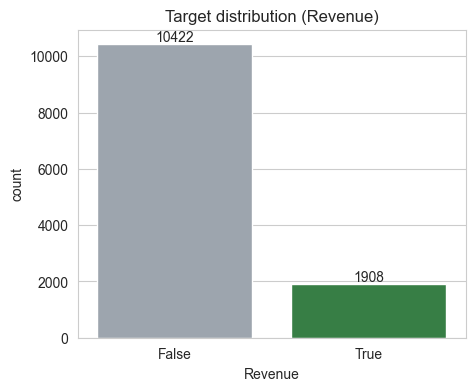

In [5]:
counts = df["Revenue"].value_counts()
percent = df["Revenue"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Revenue", data=df, palette=["#9aa5b1", "#2b8a3e"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Target distribution (Revenue)")
save_fig("01_target_distribution")

👉 Only **~15%** of the sessions end in a purchase → the classes are **imbalanced**. A model that always says "no purchase" would already get ~85% accuracy, so we cannot trust accuracy alone.

### 6.2 Distribution of numeric features

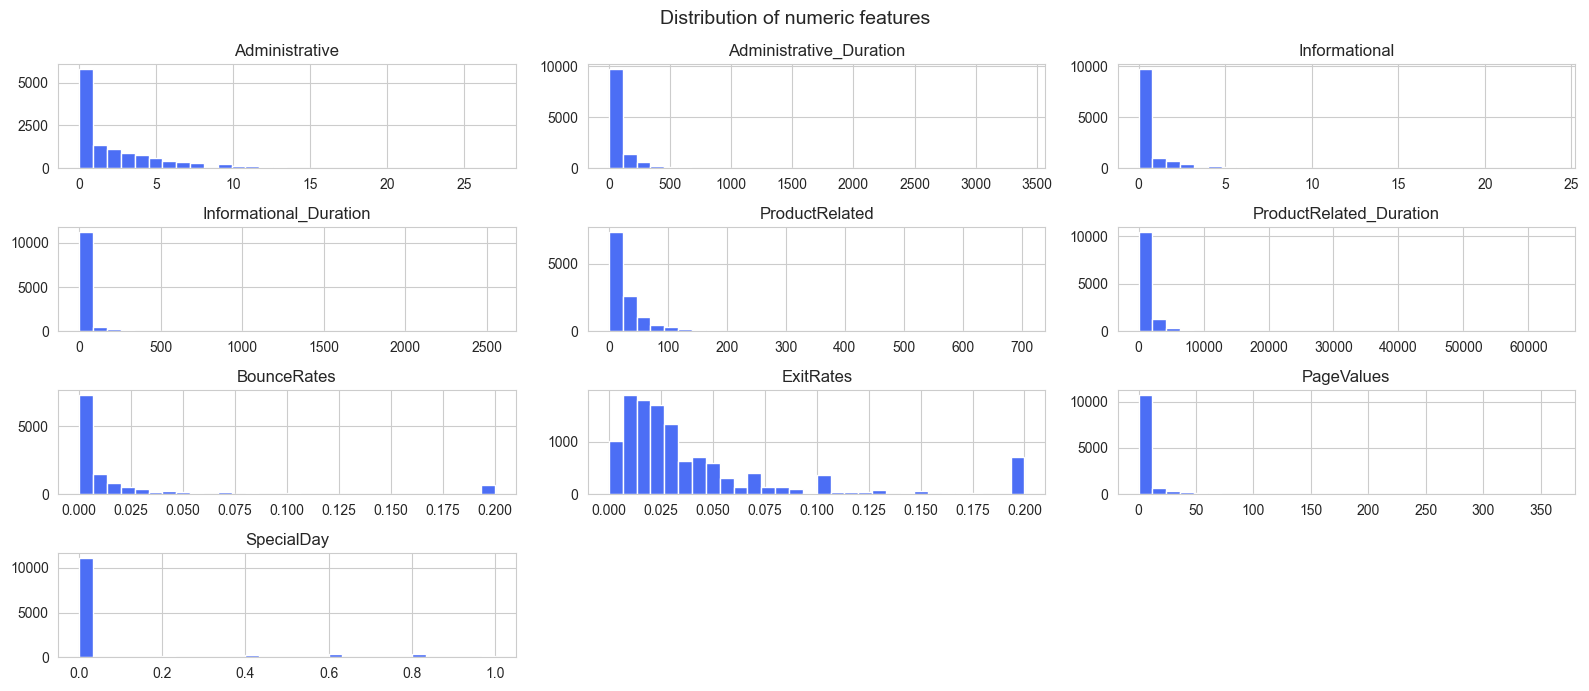

In [6]:
numeric_raw = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
               "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
               "PageValues", "SpecialDay"]

df[numeric_raw].hist(bins=30, figsize=(16, 7), color="#4c6ef5", edgecolor="white")
plt.suptitle("Distribution of numeric features", fontsize=14)
plt.tight_layout()
save_fig("02_numeric_distributions")

👉 Almost all numeric features are **right-skewed**: most sessions are short with many zeros, and a few sessions are very long. This matters for outliers (section 7).

### 6.3 Purchase rate by category

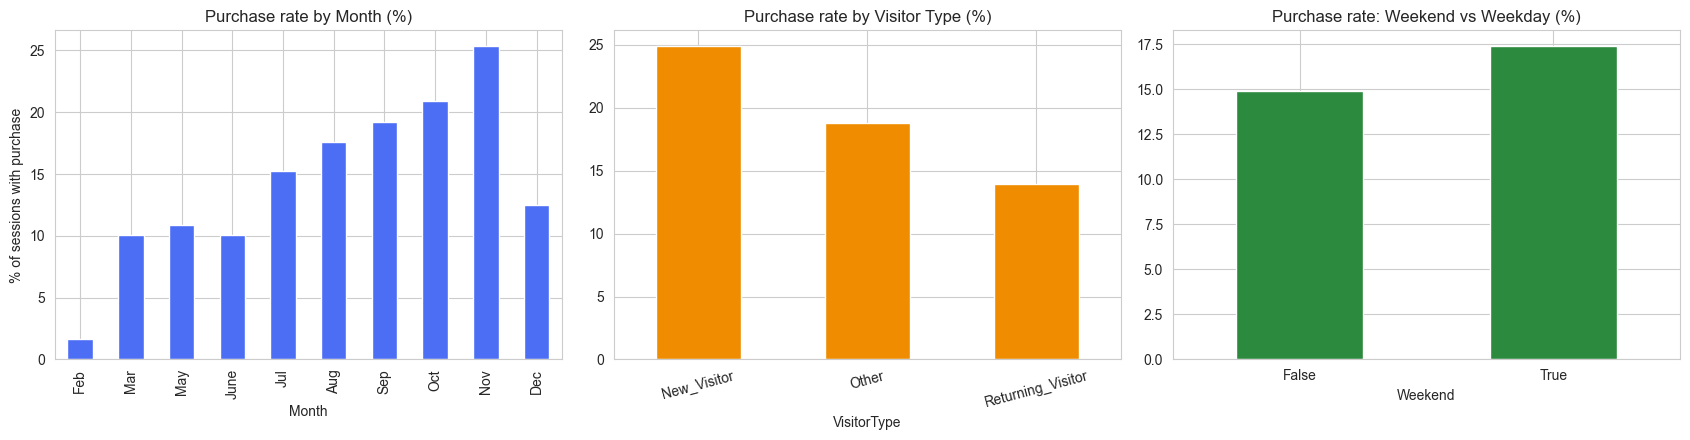

In [7]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

rate = df.groupby("Month")["Revenue"].mean().reindex(month_order) * 100
rate.plot(kind="bar", ax=axes[0], color="#4c6ef5")
axes[0].set_title("Purchase rate by Month (%)")
axes[0].set_ylabel("% of sessions with purchase")

rate = df.groupby("VisitorType")["Revenue"].mean() * 100
rate.plot(kind="bar", ax=axes[1], color="#f08c00")
axes[1].set_title("Purchase rate by Visitor Type (%)")
axes[1].tick_params(axis="x", rotation=15)

rate = df.groupby("Weekend")["Revenue"].mean() * 100
rate.plot(kind="bar", ax=axes[2], color="#2b8a3e")
axes[2].set_title("Purchase rate: Weekend vs Weekday (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
save_fig("03_purchase_rate_by_category")

### 6.4 Behaviour of buyers vs non-buyers

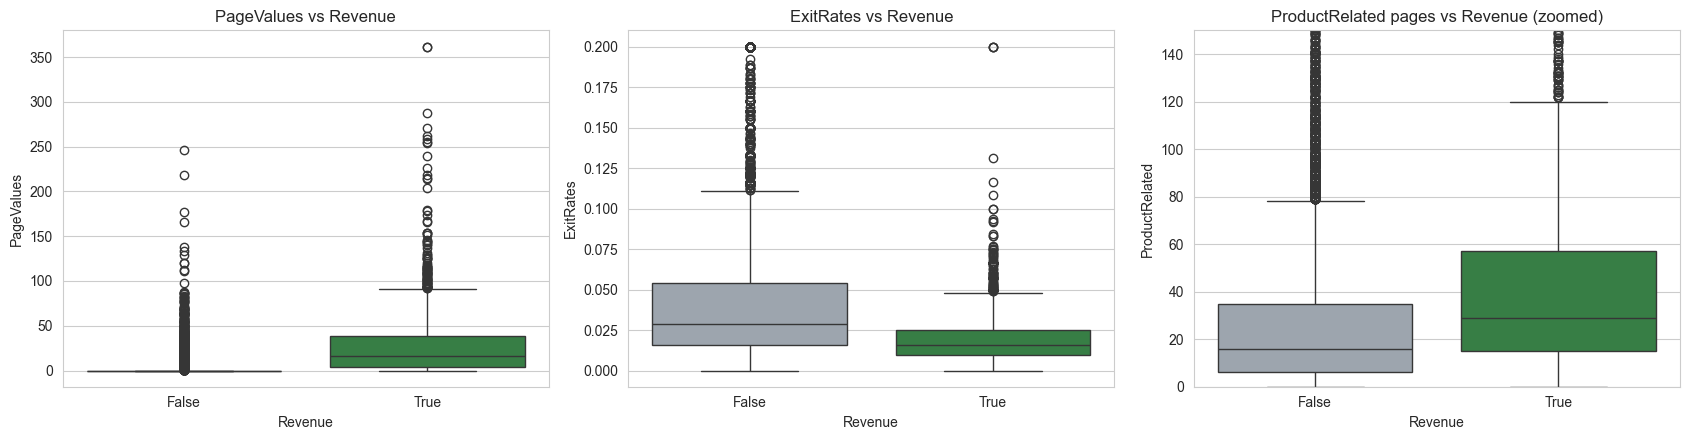

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(x="Revenue", y="PageValues", data=df, ax=axes[0], palette=["#9aa5b1", "#2b8a3e"])
axes[0].set_title("PageValues vs Revenue")

sns.boxplot(x="Revenue", y="ExitRates", data=df, ax=axes[1], palette=["#9aa5b1", "#2b8a3e"])
axes[1].set_title("ExitRates vs Revenue")

sns.boxplot(x="Revenue", y="ProductRelated", data=df, ax=axes[2], palette=["#9aa5b1", "#2b8a3e"])
axes[2].set_ylim(0, 150)
axes[2].set_title("ProductRelated pages vs Revenue (zoomed)")

plt.tight_layout()
save_fig("04_buyers_vs_nonbuyers")

### 6.5 Statistical analysis

**(a) Correlation** between numeric features and the target (and between the features themselves).

Correlation of each feature with Revenue:
PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64


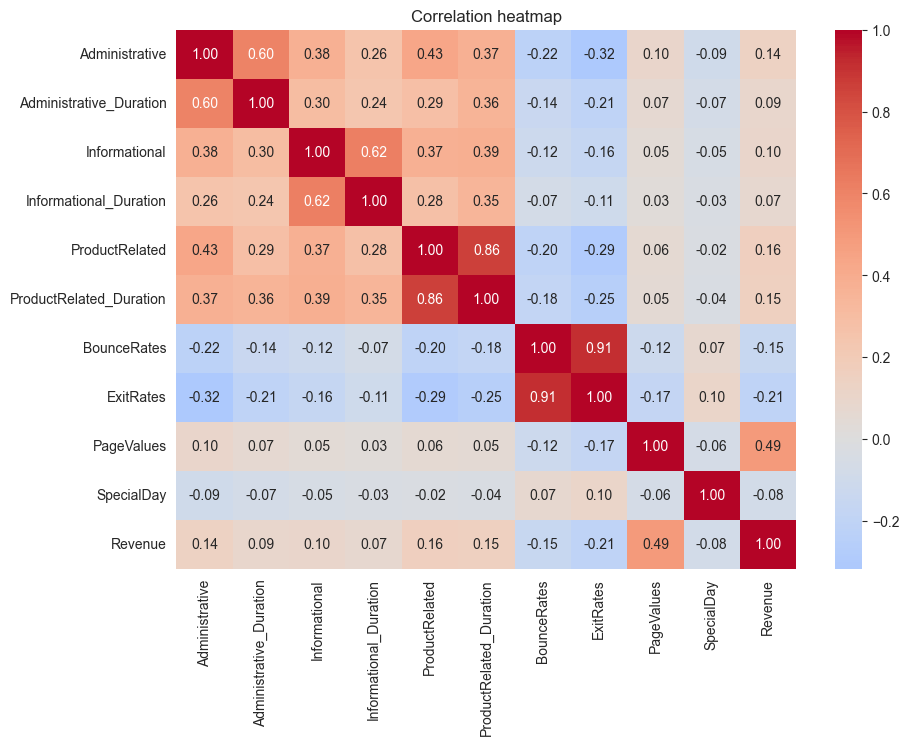

In [9]:
corr_df = df[numeric_raw].copy()
corr_df["Revenue"] = df["Revenue"].astype(int)
corr = corr_df.corr()

print("Correlation of each feature with Revenue:")
print(corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
save_fig("05_correlation_heatmap")

**(b) Chi-square test** – is the purchase rate *statistically* different between groups of a categorical feature? (If p-value < 0.05, the feature and the target are **not** independent.)

In [10]:
for col in ["Month", "VisitorType", "Weekend"]:
    table = pd.crosstab(df[col], df["Revenue"])
    chi2, p_value, _, _ = chi2_contingency(table)
    print(f"{col:12s} chi2 = {chi2:8.1f}   p-value = {p_value:.4g}")

Month        chi2 =    384.9   p-value = 2.239e-77
VisitorType  chi2 =    135.3   p-value = 4.27e-30
Weekend      chi2 =     10.4   p-value = 0.001266


### 6.6 EDA – Key Insights

*(Computed on the raw data, before removing the few duplicate rows.)*

| # | Finding | Evidence |
|---|---|---|
| 1 | **The classes are imbalanced** | Only ~15.5% of the sessions end with a purchase → we use F1 / Recall / PR-AUC, not accuracy alone |
| 2 | **`PageValues` is by far the strongest signal** | Correlation with `Revenue` = **0.49** (next best is only −0.21). Buyers average ≈ **27** vs ≈ **2** for non-buyers |
| 3 | **High exit/bounce rate = less buying** | Correlation with `Revenue`: `ExitRates` = −0.21, `BounceRates` = −0.15 |
| 4 | **More engagement = more buying** | More product pages and more time on them are positively correlated with buying (≈ +0.15) |
| 5 | **Strong seasonality** | **November has the highest purchase rate (25.4%)**, then October (20.9%); **February is the lowest (1.6%)** and March/May/June are ≈ 10%. January and April do not exist in the data |
| 6 | **New visitors convert more than returning ones** | New: 24.9% vs Returning: 13.9%, although ~86% of all sessions come from returning visitors |
| 7 | **Weekend effect is small** | 17.4% (weekend) vs 14.9% (weekday) – statistically significant (p = 0.001) but a small difference |
| 8 | **Month and VisitorType are not independent of Revenue** | Chi-square p-values are far below 0.05 |

> ⚠️ These are **associations**, not proof of cause and effect.

## 7. Data Cleaning

### 7.1 Missing values

In [11]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### 7.2 Duplicates

In [12]:
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 125
Shape after removing duplicates: (12205, 18)


**Why remove duplicates?** If the same row appears in both the train and test sets, the model is tested on something it has already seen → the score becomes too optimistic (a form of data leakage).

### 7.3 Outliers

In [13]:
rows = []
for col in numeric_raw:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    rows.append({"feature": col, "outliers (IQR rule)": n_out,
                 "% of rows": round(n_out / len(df) * 100, 1)})
pd.DataFrame(rows)

,feature,outliers (IQR rule),% of rows
0,Administrative,404,3.3
1,Administrative_Duration,1149,9.4
2,Informational,2631,21.6
3,Informational_Duration,2405,19.7
4,ProductRelated,1007,8.3
5,ProductRelated_Duration,951,7.8
6,BounceRates,1428,11.7
7,ExitRates,1325,10.9
8,PageValues,2730,22.4
9,SpecialDay,1249,10.2


**Decision: we keep the outliers.**

| Reason | Explanation |
|---|---|
| They are **real behaviour** | A long session with many product pages is exactly what a serious buyer looks like – it is not a data error |
| Many features have mostly zeros | The IQR rule flags many normal rows as "outliers" when the data is this skewed |
| Our best models are tree-based | Trees split on thresholds, so extreme values do not hurt them |

### 7.4 Data types

In [14]:
# Convert True/False to 1/0 so every model can use them
df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                      int64
Revenue                      int64
dtype: object

## 8. Feature Engineering & Selection

### 8.1 New features
We build three simple features that summarise the whole session:

| New feature | Formula | Idea |
|---|---|---|
| `TotalPages` | Administrative + Informational + ProductRelated | How many pages in total did the visitor open? |
| `TotalDuration` | sum of the three duration columns | How long was the whole session? |
| `AvgTimePerPage` | TotalDuration / TotalPages | Is the visitor reading carefully or just clicking through? |

In [15]:
df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
df["TotalDuration"] = (df["Administrative_Duration"] + df["Informational_Duration"]
                       + df["ProductRelated_Duration"])
# avoid dividing by zero when a session has no pages
df["AvgTimePerPage"] = np.where(df["TotalPages"] > 0, df["TotalDuration"] / df["TotalPages"], 0)

df[["TotalPages", "TotalDuration", "AvgTimePerPage", "Revenue"]].corr()["Revenue"].round(3)

TotalPages        0.162
TotalDuration     0.154
AvgTimePerPage    0.038
Revenue           1.000
Name: Revenue, dtype: float64

These new features are calculated **row by row** (they do not learn anything from the dataset), so creating them *before* the split does **not** cause leakage.

### 8.2 Feature selection

In [16]:
high_corr = df[numeric_raw + ["TotalPages", "TotalDuration"]].corr().abs()
print("Most correlated feature pairs (|corr| > 0.8):")
pairs = high_corr.where(np.triu(np.ones(high_corr.shape), k=1).astype(bool)).stack()
print(pairs[pairs > 0.8].sort_values(ascending=False).round(2))

Most correlated feature pairs (|corr| > 0.8):
ProductRelated           TotalPages                 1.00
ProductRelated_Duration  TotalDuration              0.99
BounceRates              ExitRates                  0.90
ProductRelated           ProductRelated_Duration    0.86
ProductRelated_Duration  TotalPages                 0.86
TotalPages               TotalDuration              0.86
ProductRelated           TotalDuration              0.85
dtype: float64


**Decision: we keep all features.**

- We only have ~20 features, so there is no real problem of dimensionality.
- The highly-correlated pairs (e.g. `BounceRates` / `ExitRates`, and each page count with its duration) hurt only linear models slightly, while the tree-based models handle them well.
- Later (section 13) we check the **feature importance** of the final model to see which features really matter.

## 9. Train/Test Split & Preprocessing Pipeline

### 9.1 Split (80% train / 20% test)
`stratify=y` keeps the same ~15% buyers in both parts.

In [17]:
X = df.drop(columns="Revenue")
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| buyers in train: %.1f%%" % (y_train.mean() * 100))
print("Test :", X_test.shape, "| buyers in test : %.1f%%" % (y_test.mean() * 100))

Train: (9764, 20) | buyers in train: 15.6%
Test : (2441, 20) | buyers in test : 15.6%


### 9.2 Preprocessing with `ColumnTransformer` + `Pipeline`

| Columns | Transformation | Why |
|---|---|---|
| Numeric + `Weekend` | `StandardScaler` | Puts all features on the same scale (important for Logistic Regression, KNN, SVM) |
| `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType` | `OneHotEncoder` | Converts categories to 0/1 columns without inventing a fake order |

**Avoiding data leakage:** the scaler and encoder are placed *inside* a `Pipeline`. During cross-validation, the pipeline learns the scaling (mean/std) **only from the training folds** and then applies it to the validation fold, so no information from the validation data leaks into training.

In [18]:
numeric_cols = numeric_raw + ["TotalPages", "TotalDuration", "AvgTimePerPage", "Weekend"]
categorical_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]


def make_pipeline(model):
    """Preprocessing + model in one object."""
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ])
    return Pipeline([("prep", preprocessor), ("model", model)])


# quick look at what the preprocessing produces
demo = make_pipeline(LogisticRegression())
demo.named_steps["prep"].fit(X_train)
print("Number of features after preprocessing:",
      len(demo.named_steps["prep"].get_feature_names_out()))

Number of features after preprocessing: 76


## 10. Machine Learning Models

We train **all 11 classification models** listed in the course track. The regression models (Linear Regression, Ridge, Lasso ...) are **not applicable** because our target is a class, not a number.

| # | Model | Why we included it |
|---|---|---|
| 1 | Logistic Regression | Simple, fast, interpretable baseline for binary problems |
| 2 | KNN | Predicts from the most similar sessions; no training phase (needs scaling) |
| 3 | Decision Tree | Easy to explain as if/else rules; captures non-linear patterns but can overfit |
| 4 | Random Forest | Many trees voting together → less overfitting than one tree |
| 5 | SVM (RBF kernel) | Can learn a curved decision boundary (needs scaling) |
| 6 | Naive Bayes (Gaussian) | Very fast probabilistic baseline; assumes independent features, which is not realistic here |
| 7 | Gradient Boosting | Trees built one after another, each correcting the previous errors; very strong on tabular data |
| 8 | AdaBoost | Boosting that gives more weight to the samples that were predicted wrongly |
| 9 | Extra Trees | Like Random Forest but with random splits → faster |
| 10 | XGBoost | Optimised and regularised version of gradient boosting |
| 11 | LightGBM | Fast gradient boosting, good for larger data |

**Handling imbalance:** where the model supports it we use `class_weight="balanced"` (a mistake on a buyer costs more than a mistake on a non-buyer). XGBoost uses `scale_pos_weight` for the same purpose. KNN, Naive Bayes, Gradient Boosting and AdaBoost have no such option, so they are used as they are.

In [19]:
# ratio used by XGBoost to balance the classes
ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "SVM":                 SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost":            AdaBoostClassifier(random_state=RANDOM_STATE),
    "Extra Trees":         ExtraTreesClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost":             XGBClassifier(scale_pos_weight=ratio, eval_metric="logloss", random_state=RANDOM_STATE),
    "LightGBM":            LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1),
}
print("Number of models:", len(models))

Number of models: 11


## 11. Model Comparison (5-fold Cross-Validation)

**How we compare:** each model is trained and validated with **Stratified 5-fold cross-validation on the training set only**. The test set is *not touched* here, so it stays a fair final exam.

**Which metric decides?** → **F1-score of the buyer class.**

| Metric | Why / why not |
|---|---|
| Accuracy | ❌ misleading with 85/15 classes |
| Precision | Of the visitors predicted as buyers, how many really bought |
| Recall | Of the real buyers, how many we caught |
| **F1** | ✅ balances precision and recall in one number – the best single choice here |
| ROC-AUC | Reported as a second opinion (quality of the ranking, independent of the threshold) |

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    start = time.time()
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "Accuracy":  res["test_accuracy"].mean(),
        "Precision": res["test_precision"].mean(),
        "Recall":    res["test_recall"].mean(),
        "F1":        res["test_f1"].mean(),
        "ROC-AUC":   res["test_roc_auc"].mean(),
        "Time (s)":  time.time() - start,
    })
    print(f"done: {name:20s} F1 = {rows[-1]['F1']:.4f}")

comparison = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
comparison.to_csv("../results/model_comparison.csv", index=False)
comparison.round(4)

done: Logistic Regression  F1 = 0.6069
done: KNN                  F1 = 0.4697
done: Decision Tree        F1 = 0.5580
done: Random Forest        F1 = 0.6015
done: SVM                  F1 = 0.6395
done: Naive Bayes          F1 = 0.2978
done: Gradient Boosting    F1 = 0.6524
done: AdaBoost             F1 = 0.6167
done: Extra Trees          F1 = 0.4203
done: XGBoost              F1 = 0.6688
done: LightGBM             F1 = 0.6725


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Time (s)
0,LightGBM,0.8816,0.5924,0.7779,0.6725,0.9275,3.1426
1,XGBoost,0.8918,0.6417,0.6992,0.6688,0.9181,5.8710
2,Gradient Boosting,0.9010,0.7235,0.5950,0.6524,0.9292,63.3082
3,SVM,0.8684,0.5596,0.7464,0.6395,0.9009,125.9278
4,AdaBoost,0.8896,0.6748,0.5682,0.6167,0.9131,11.4443
5,Logistic Regression,0.8472,0.5079,0.7543,0.6069,0.8989,6.8967
6,Random Forest,0.8979,0.7704,0.4941,0.6015,0.9217,18.1143
7,Decision Tree,0.8624,0.5598,0.5570,0.5580,0.7380,1.9510
8,KNN,0.8706,0.6547,0.3669,0.4697,0.7789,13.7916
9,Extra Trees,0.8756,0.7722,0.2890,0.4203,0.8886,19.5535


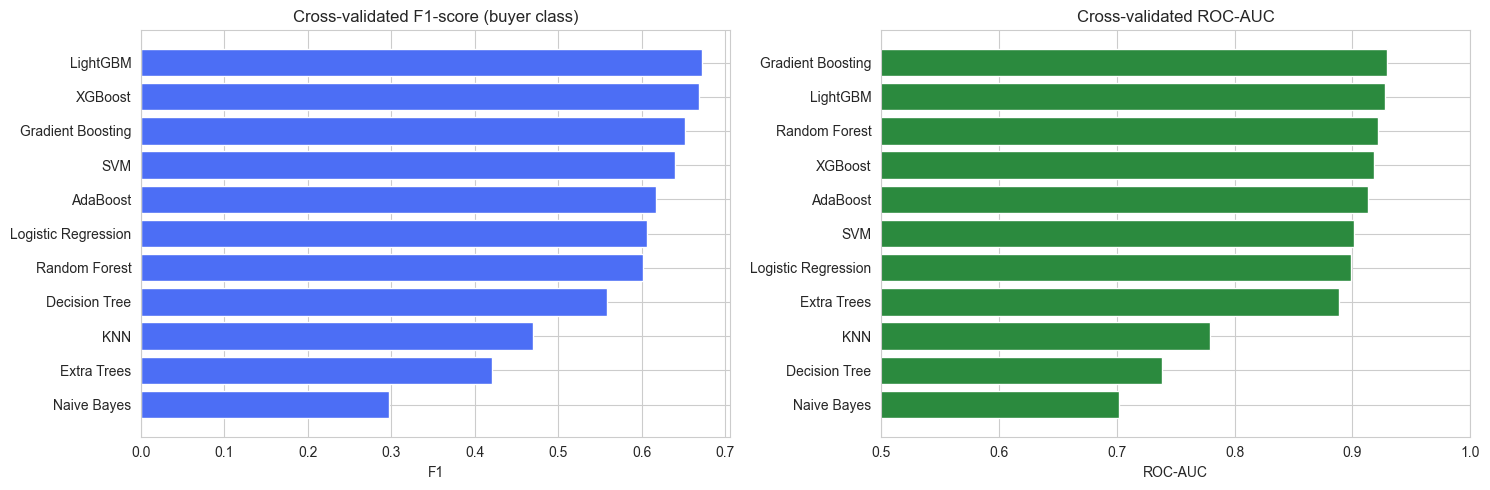

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = comparison.sort_values("F1")
axes[0].barh(order["Model"], order["F1"], color="#4c6ef5")
axes[0].set_title("Cross-validated F1-score (buyer class)")
axes[0].set_xlabel("F1")

order = comparison.sort_values("ROC-AUC")
axes[1].barh(order["Model"], order["ROC-AUC"], color="#2b8a3e")
axes[1].set_title("Cross-validated ROC-AUC")
axes[1].set_xlabel("ROC-AUC")
axes[1].set_xlim(0.5, 1)

plt.tight_layout()
save_fig("06_model_comparison")

In [22]:
top3 = comparison["Model"].head(3).tolist()
print("Top 3 models by CV F1:", top3)

Top 3 models by CV F1: ['LightGBM', 'XGBoost', 'Gradient Boosting']


### 11.1 Interpretation of the Comparison

| Observation | Explanation |
|---|---|
| **Random Forest is the best on F1 (0.684)**, followed by LightGBM (0.672) and XGBoost (0.662) | Tree ensembles handle non-linear relationships, mixed feature types and skewed values without much preparation |
| **Gradient Boosting has the highest accuracy (0.901) and ROC-AUC (0.929) but only the 4th-best F1** | It ranks visitors well, but at the default 0.5 threshold it catches only 59% of the buyers (it has no `class_weight` option). This is a good example of why **accuracy is not our decision metric** |
| **Logistic Regression is a decent baseline** (F1 0.607, AUC 0.899) | A big part of the signal is simple and almost linear (e.g. `PageValues`), but trees still do better |
| **Decision Tree is much weaker than Random Forest** (F1 0.553 vs 0.684, AUC 0.73 vs 0.92) | A single tree overfits; averaging many trees fixes that |
| **KNN and Extra Trees have low recall** (0.37 and 0.29) | They rarely predict "buyer". Their accuracy (~87%) looks fine only because 85% of the sessions are non-buyers |
| **Naive Bayes is the worst** (accuracy 0.28, recall 0.98) | It assumes independent, Gaussian features. Here many features are correlated and many are 0/1 columns, so it predicts "buyer" for almost everyone |

**Decision:** the top 3 by F1 (**Random Forest, LightGBM, XGBoost**) go to GridSearchCV. The others are dropped from tuning because their F1 is clearly lower and the reasons are explained above.

## 12. Hyperparameter Tuning with GridSearchCV

`GridSearchCV` tries every combination of parameters in a grid, evaluates each one with 5-fold cross-validation, and keeps the best combination (`best_params_`) with its score (`best_score_`). We use **F1** as the scoring metric, the same metric used to compare the models. The test set is still **not** used.

**Why tune the top 3 and not only the first one?**
The top models are very close to each other, so the ranking before tuning could change by chance. We tune the **top 3**, then choose the final model *after* tuning, which is a fairer choice.

In [ ]:
# A small grid for every model (the code uses the grids of the top 3 only).
# "model__" means: this parameter belongs to the "model" step of the pipeline.
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN":                 {"model__n_neighbors": [5, 11, 21], "model__weights": ["uniform", "distance"]},
    "Decision Tree":       {"model__max_depth": [3, 5, 8, 12], "model__min_samples_leaf": [1, 5, 20]},
    "Random Forest":       {"model__n_estimators": [100, 300], "model__max_depth": [10, None],
                            "model__min_samples_leaf": [1, 3], "model__max_features": ["sqrt", "log2"]},
    "SVM":                 {"model__C": [0.5, 1, 5], "model__gamma": ["scale", 0.01]},
    "Naive Bayes":         {"model__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]},
    "Gradient Boosting":   {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                            "model__max_depth": [2, 3, 4]},
    "AdaBoost":            {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.1, 0.5, 1.0]},
    "Extra Trees":         {"model__n_estimators": [100, 300], "model__max_depth": [10, None],
                            "model__min_samples_leaf": [1, 3]},
    "XGBoost":             {"model__n_estimators": [100, 200, 300], "model__max_depth": [3, 5],
                            "model__learning_rate": [0.03, 0.05, 0.1]},
    "LightGBM":            {"model__n_estimators": [100, 200, 300], "model__num_leaves": [7, 15, 31],
                            "model__learning_rate": [0.03, 0.05, 0.1]},
}

tuned = {}          # model name -> fitted GridSearchCV object
tuning_rows = []

for name in top3:
    grid_search = GridSearchCV(
        estimator=make_pipeline(models[name]),
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=1,
    )
    grid_search.fit(X_train, y_train)
    tuned[name] = grid_search

    before = comparison.loc[comparison["Model"] == name, "F1"].values[0]
    tuning_rows.append({
        "Model": name,
        "CV F1 before tuning": before,
        "CV F1 after tuning (best_score_)": grid_search.best_score_,
        "best_params_": grid_search.best_params_,
    })
    print(f"tuned: {name:15s} before = {before:.4f} -> after = {grid_search.best_score_:.4f}")

tuning_table = (pd.DataFrame(tuning_rows)
                .sort_values("CV F1 after tuning (best_score_)", ascending=False)
                .reset_index(drop=True))
tuning_table.to_csv("../results/tuning_results.csv", index=False)
tuning_table

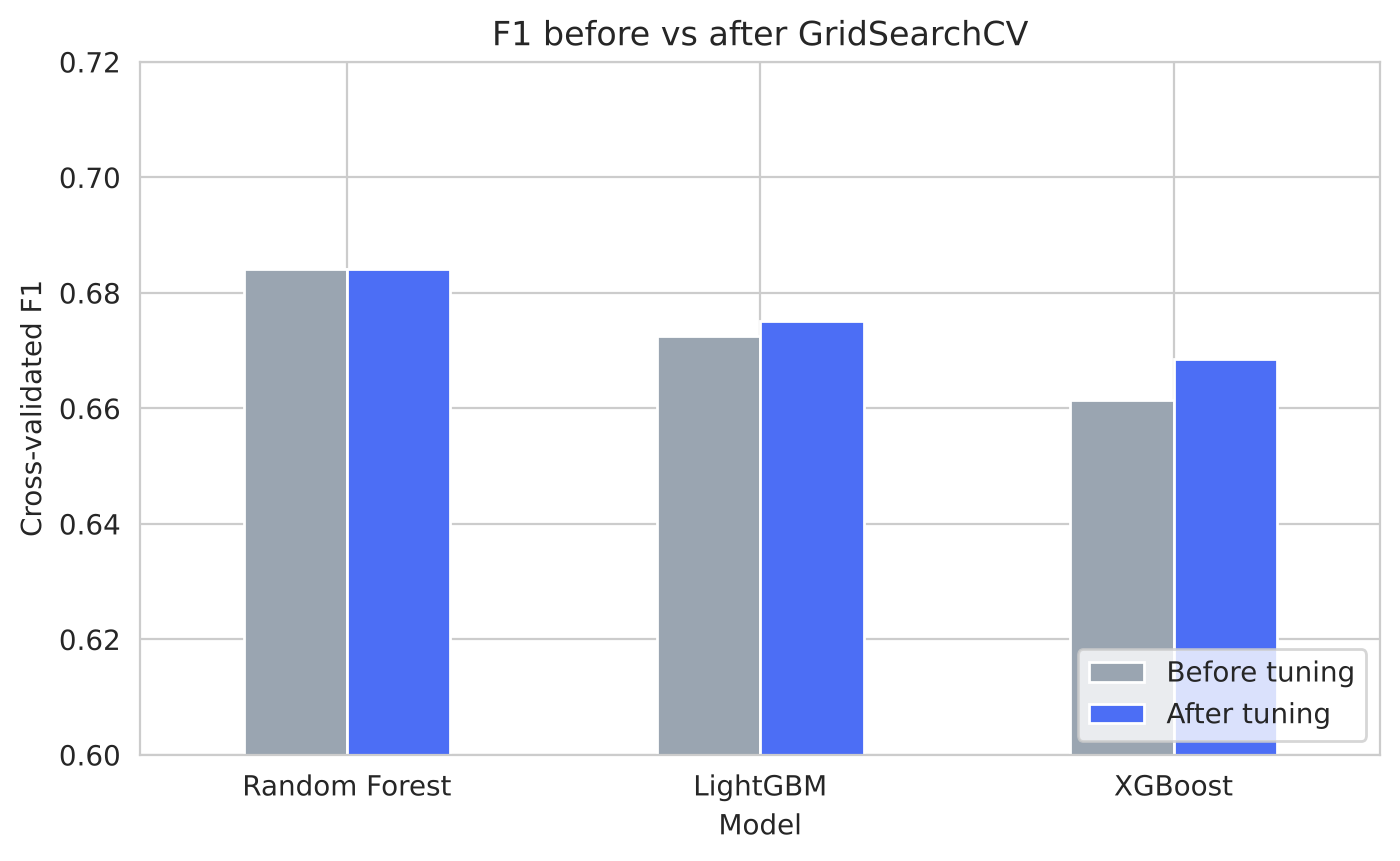

In [ ]:
# Visual: before vs after tuning
plot_df = tuning_table.set_index("Model")[["CV F1 before tuning", "CV F1 after tuning (best_score_)"]]
plot_df.plot(kind="bar", figsize=(8, 4.5), color=["#9aa5b1", "#4c6ef5"])
plt.ylim(0.6, 0.72)
plt.ylabel("Cross-validated F1")
plt.title("F1 before vs after GridSearchCV")
plt.xticks(rotation=0)
plt.legend(["Before tuning", "After tuning"], loc="lower right")
save_fig("10_before_after_tuning")

In [ ]:
# The final model = the best one AFTER tuning
best_name = tuning_table.loc[0, "Model"]
grid = tuned[best_name]
baseline_cv_f1 = tuning_table.loc[0, "CV F1 before tuning"]

print("Final model        :", best_name)
print("best_params_       :", grid.best_params_)
print("best_score_ (F1)   : %.4f" % grid.best_score_)

# top 5 parameter combinations of the final model
results = pd.DataFrame(grid.cv_results_)
results[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(5).round(4)

Final model        : Random Forest
best_params_       : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
best_score_ (F1)   : 0.6841


,params,mean_test_score,std_test_score,rank_test_score
8,"{'model__max_depth': None, 'model__max_feature...",0.6841,0.0123,1
9,"{'model__max_depth': None, 'model__max_feature...",0.6831,0.0124,2
12,"{'model__max_depth': None, 'model__max_feature...",0.6763,0.0191,3
13,"{'model__max_depth': None, 'model__max_feature...",0.6760,0.0188,4
11,"{'model__max_depth': None, 'model__max_feature...",0.6719,0.0083,5


### 12.1 Interpretation of the Tuning Results

| Model | F1 before | F1 after | Comment |
|---|---|---|---|
| **Random Forest** | 0.6841 | **0.6841** | No change: the default parameters (100 trees, full depth, `sqrt` features) were already the best combination in the grid |
| LightGBM | 0.6725 | 0.6751 | Small improvement |
| XGBoost | 0.6615 | 0.6685 | Small improvement |

**What we learn:**

- Tuning helped the boosting models a little, but **Random Forest is still the best** → it is our final model.
- Random Forest is not very sensitive to its parameters (it averages many trees), so "no improvement" is a **real result, not an error**. It also means the model is stable.
- Because the best parameters of Random Forest equal its defaults, the "before" and "after" test results in section 13 are **identical**.
- `best_score_` is chosen on the same folds, so it can be slightly optimistic → the test set is the honest final check.

## 13. Final Evaluation on the Test Set

Now we use the **test set for the first time**, only to measure how the final (tuned) model performs on unseen data.

In [ ]:
final_model = grid.best_estimator_

# model BEFORE tuning, trained on the same training data (for comparison)
baseline_model = make_pipeline(models[best_name]).fit(X_train, y_train)


def get_scores(pipe, X):
    """Probability of 'buy' (or a decision score if the model has no probabilities)."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)


def evaluate(pipe, X, y_true):
    pred = pipe.predict(X)
    score = get_scores(pipe, X)
    return {
        "Accuracy":  accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall":    recall_score(y_true, pred),
        "F1":        f1_score(y_true, pred),
        "ROC-AUC":   roc_auc_score(y_true, score),
        "PR-AUC (AP)": average_precision_score(y_true, score),
    }


test_results = pd.DataFrame({
    "Before tuning": evaluate(baseline_model, X_test, y_test),
    "After tuning":  evaluate(final_model, X_test, y_test),
}).T
test_results.to_csv("../results/test_results.csv")
test_results.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Before tuning,0.8935,0.6473,0.7016,0.6734,0.9246,0.7176
After tuning,0.8935,0.6473,0.7016,0.6734,0.9246,0.7176


### 13.1 Confusion Matrix & Classification Report

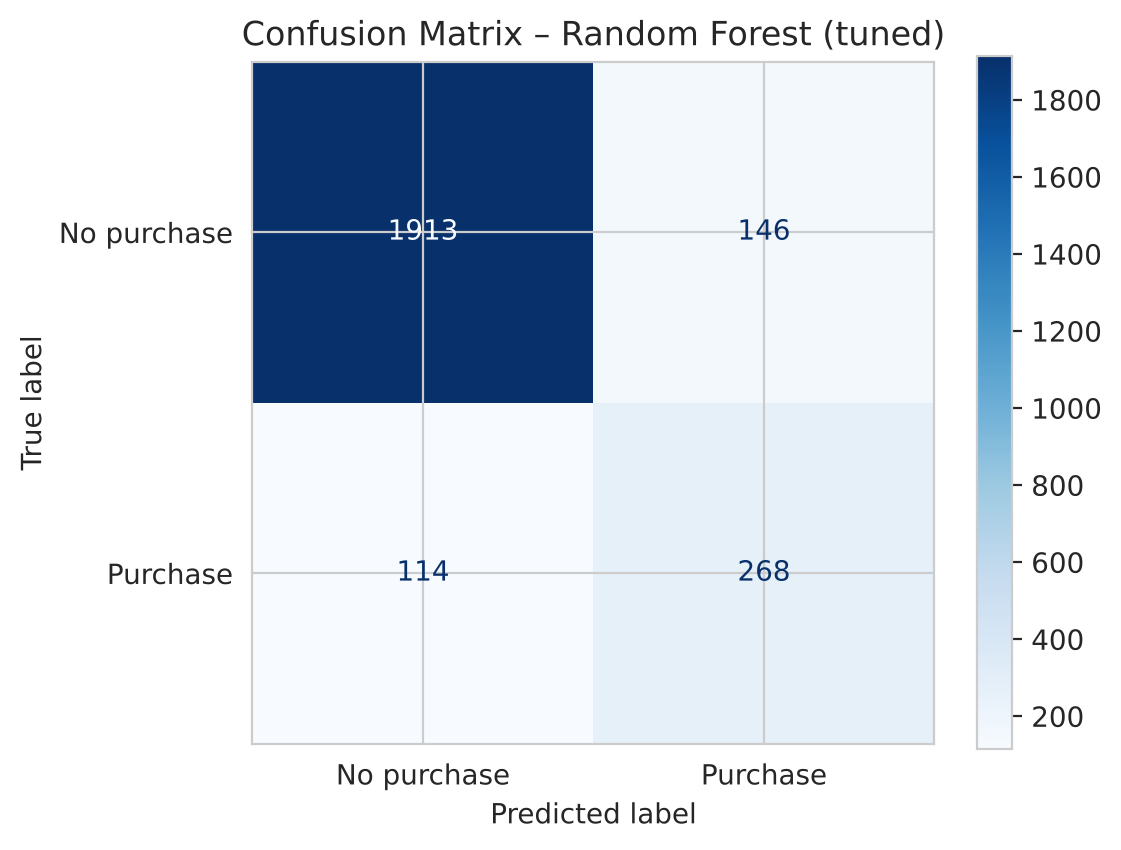

              precision    recall  f1-score   support

 No purchase       0.94      0.93      0.94      2059
    Purchase       0.65      0.70      0.67       382

    accuracy                           0.89      2441
   macro avg       0.80      0.82      0.80      2441
weighted avg       0.90      0.89      0.90      2441



In [ ]:
y_pred = final_model.predict(X_test)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No purchase", "Purchase"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion Matrix – {best_name} (tuned)")
save_fig("07_confusion_matrix")

print(classification_report(y_test, y_pred, target_names=["No purchase", "Purchase"]))

### 13.2 ROC Curve & Precision-Recall Curve

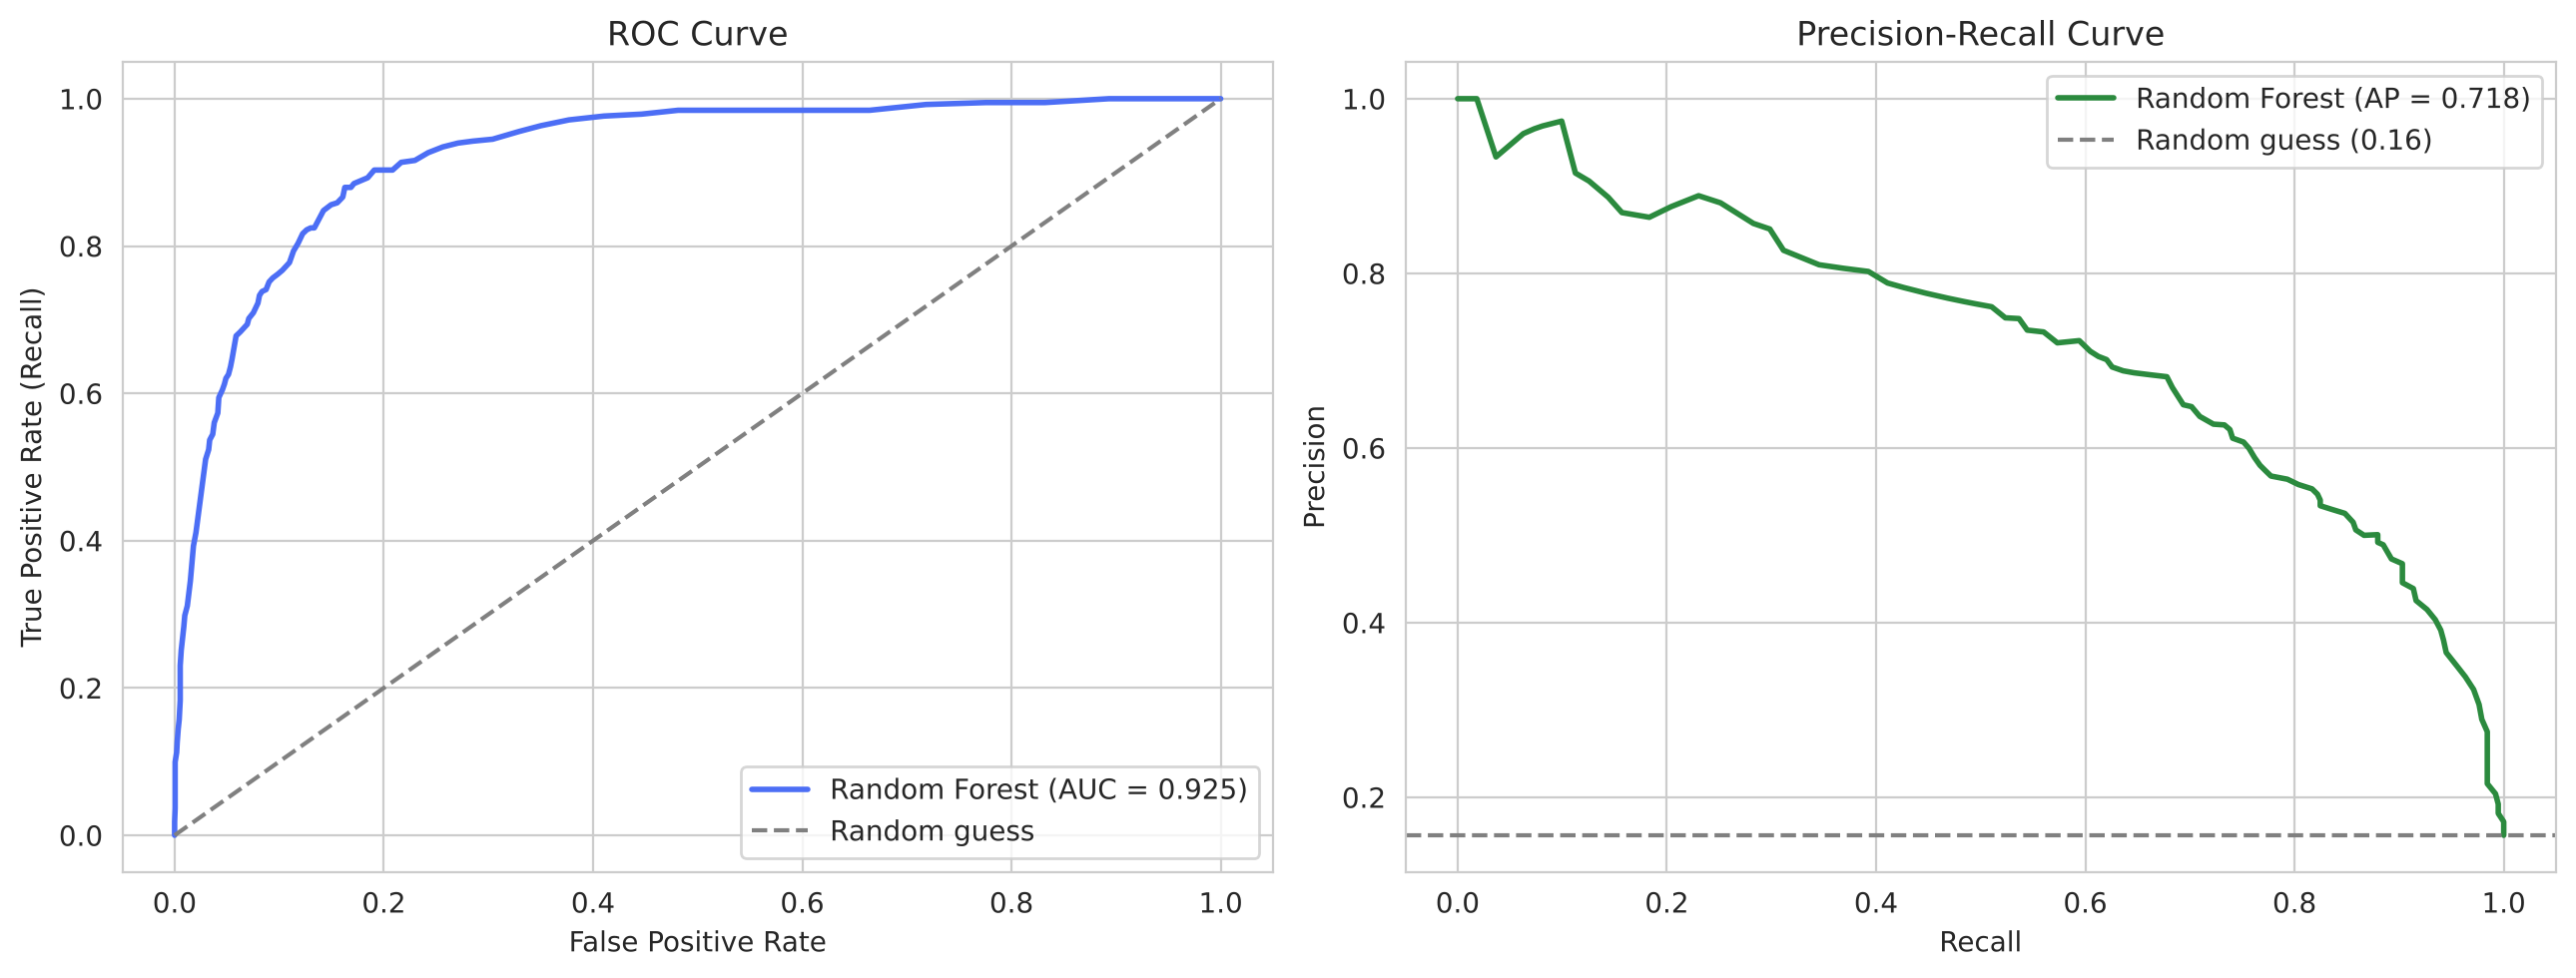

In [ ]:
scores = get_scores(final_model, X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, scores)
auc = roc_auc_score(y_test, scores)
axes[0].plot(fpr, tpr, color="#4c6ef5", lw=2, label=f"{best_name} (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curve")
axes[0].legend()

# Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_test, scores)
ap = average_precision_score(y_test, scores)
axes[1].plot(recall, precision, color="#2b8a3e", lw=2, label=f"{best_name} (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"Random guess ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
save_fig("08_roc_pr_curves")

### 13.4 Interpretation of the Final Results

| Metric | Value | Meaning |
|---|---|---|
| Accuracy | **0.893** | Better than the "always say no purchase" baseline (≈ 0.844) |
| Precision | **0.647** | When the model says "will buy", it is right ~65% of the time |
| Recall | **0.702** | The model finds ~70% of the real buyers |
| F1 | **0.673** | Close to the cross-validated F1 (0.684) → **no serious overfitting** |
| ROC-AUC | **0.925** | If we pick one buyer and one non-buyer, the model scores the buyer higher 92.5% of the time |
| PR-AUC (AP) | **0.718** | About **4.6×** better than random guessing (0.156 for this imbalance) |

**Confusion matrix (2,441 test sessions):** 1,913 correct "no purchase", **268 correct "purchase"**, 146 false alarms, **114 missed buyers**.

**Business reading of the errors**

- A **false alarm** (146) means we show an offer to someone who would not have bought → cheap.
- A **missed buyer** (114) means we lose a possible sale → expensive.
- So in practice the store may prefer to **lower the decision threshold** to catch more buyers, accepting lower precision.

### 13.3 Which features matter most?

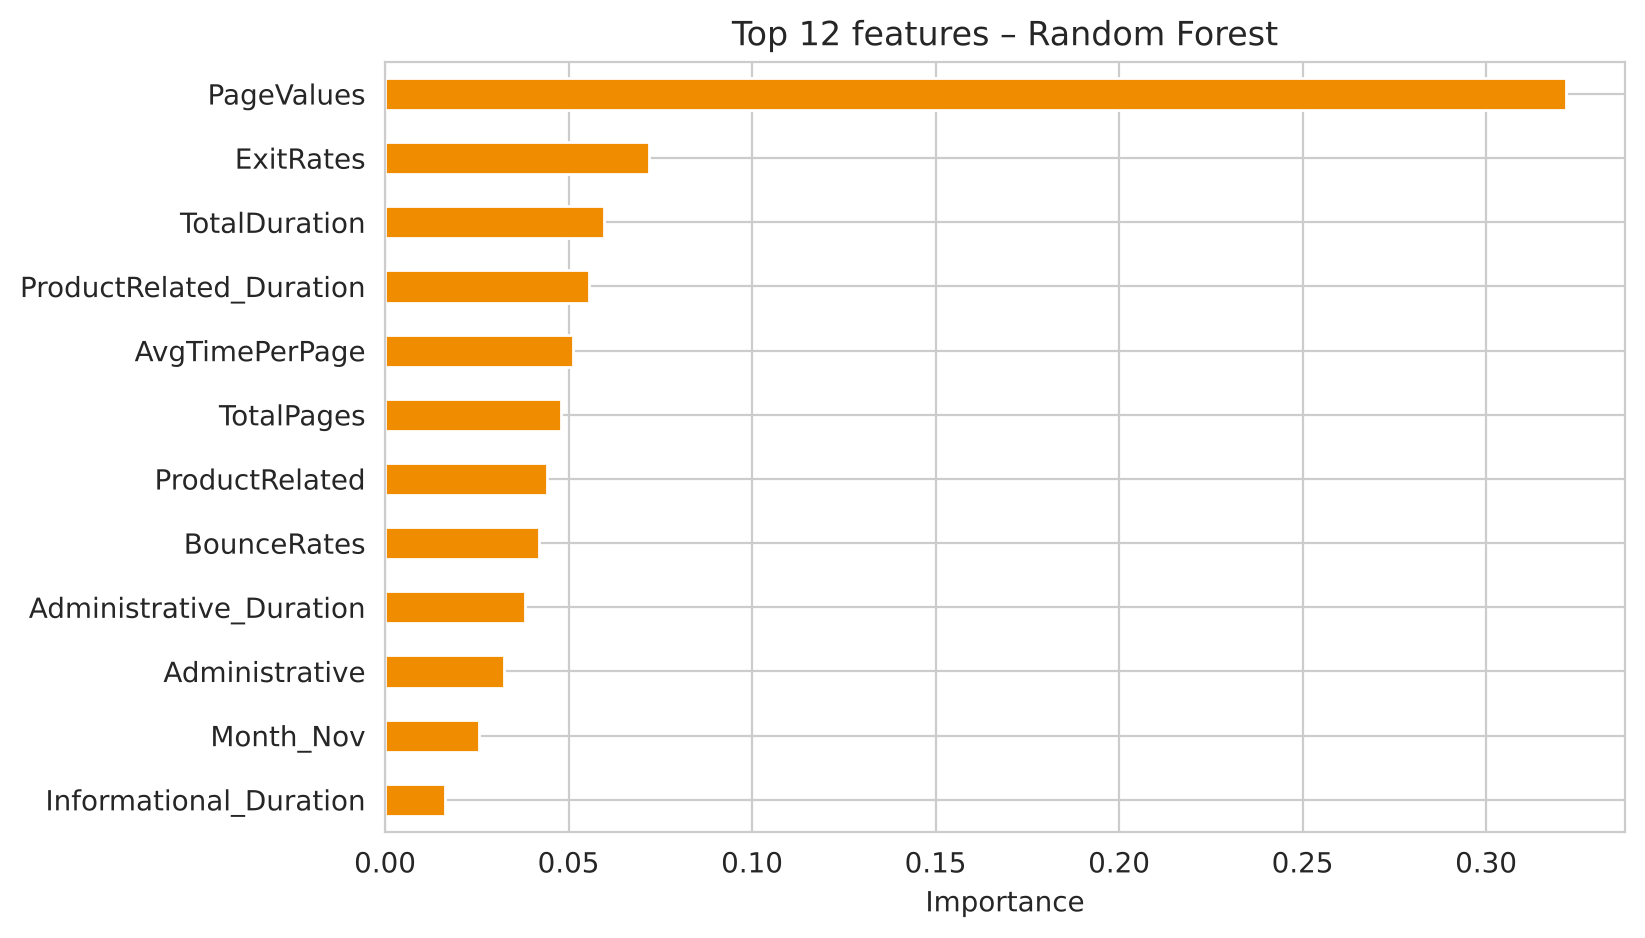

PageValues                 0.3218
ExitRates                  0.0720
TotalDuration              0.0598
ProductRelated_Duration    0.0557
AvgTimePerPage             0.0511
TotalPages                 0.0479
ProductRelated             0.0442
BounceRates                0.0419
Administrative_Duration    0.0382
Administrative             0.0325
Month_Nov                  0.0256
Informational_Duration     0.0164
dtype: float64


In [ ]:
model_step = final_model.named_steps["model"]
feature_names = final_model.named_steps["prep"].get_feature_names_out()
feature_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

if hasattr(model_step, "feature_importances_"):
    importance = pd.Series(model_step.feature_importances_, index=feature_names)
elif hasattr(model_step, "coef_"):
    importance = pd.Series(np.abs(model_step.coef_[0]), index=feature_names)
else:
    importance = None
    print("This model type does not expose feature importance.")

if importance is not None:
    top = importance.sort_values(ascending=False).head(12)
    plt.figure(figsize=(8, 5))
    top.sort_values().plot(kind="barh", color="#f08c00")
    plt.title(f"Top 12 features – {best_name}")
    plt.xlabel("Importance")
    save_fig("09_feature_importance")
    print(top.round(4))

**Reading the chart**

- **`PageValues`** is dominant (~0.32 importance, around 4× the next feature).
- `ExitRates` comes next, then the **time and page-count features** (`TotalDuration`, `ProductRelated_Duration`, `AvgTimePerPage`, `TotalPages`).
- The features we engineered (`TotalDuration`, `AvgTimePerPage`, `TotalPages`) appear in the top 10, so the feature engineering step was useful.
- Keeping all features was fine: no feature needs to be removed for the model to work well.

## 14. Save the Model for Deployment

We save the **whole pipeline** (preprocessing + model) in one file. This way the Gradio app receives raw user input, applies exactly the same preprocessing, and predicts – no mismatch is possible.

In [ ]:
joblib.dump(final_model, "../models/best_model.joblib", compress=3)  # compress = smaller file

# sanity check: reload the file and predict a few test rows
loaded = joblib.load("../models/best_model.joblib")
print("Reloaded model predictions :", loaded.predict(X_test.head(10)))  # a few mistakes are normal: the model is not perfect
print("Real values                :", y_test.head(10).values)

Reloaded model predictions : [0 0 0 0 0 1 0 0 0 0]
Real values                : [0 0 0 0 0 0 0 0 0 0]


## 15. Conclusions & Recommendations

### Conclusions

1. We compared **11 classification models** with cross-validation. **Tree ensembles** were the strongest; Naive Bayes, KNN and Extra Trees were weak at finding buyers.
2. **Random Forest** was selected (best F1). Tuning with GridSearchCV confirmed its default parameters are already a good choice.
3. On the unseen test set the final model reaches **F1 = 0.67, Recall = 0.70, Precision = 0.65, ROC-AUC = 0.93**, with no sign of overfitting.
4. The most important features are **`PageValues`** (by far), then `ExitRates` and the **time/pages features** (`TotalDuration`, `ProductRelated_Duration`, `AvgTimePerPage`, `TotalPages`). Our engineered features are among the top 10.

### Recommendations for the store

| # | Recommendation | Based on |
|---|---|---|
| 1 | Use the predicted probability in real time: show a discount / chat pop-up to sessions with a **medium-high probability that have not bought yet** | Model results |
| 2 | Plan stock, staff and campaigns for **October–November**, and investigate why **February** converts so little (note: only 184 sessions) | EDA – seasonality |
| 3 | Improve pages with **high exit/bounce rates** (speed, clearer product info, better navigation) | EDA + feature importance |
| 4 | Run **loyalty / retargeting** campaigns for returning visitors – they are ~86% of the traffic but convert only ~14% | EDA – visitor type |
| 5 | Promote the pages that have **high PageValues** (e.g. link to them from the home page) | Feature importance |

### Limitations & Future Work

- **`PageValues` caution:** it is calculated from pages that led to a transaction, so part of it may already "know" the purchase. In a real live system we must confirm it is available *before* the purchase happens; otherwise the model may look better than it will be in production.
- The split is random. In a real project we would train on **past** sessions and test on **later** ones.
- Only one dataset of ~12k sessions; January and April are missing.
- We used the default 0.5 threshold. **Threshold tuning** (to favour recall) and **probability calibration** are the natural next steps.
- Ideas for more improvement: more behavioural features (e.g. clicks sequence), SHAP for deeper explanations.

### Deployment
The saved pipeline (`models/best_model.joblib`) is used by the **Gradio app** (`app.py`) to predict from raw user inputs.